# Цены на квартиры в Петербурге и Ленинградской области

Учебный проект Яндекс Практикума · Данные сервиса Яндекс Недвижимость

Как подобрать похожие квартиры для оценки цены? Я изучил 23 699 объявлений, опубликованных с ноября 2014 по май 2019 года. Сравнил квартиры по площади и этажу, посмотрел, как менялась цена по мере удаления от центра Петербурга, и отдельно разобрал срок размещения.

**Что получилось.** Из изученных характеристик квартиры теснее всего с полной ценой связана общая площадь (ранговая корреляция 0,75). Среди десяти населённых пунктов с наибольшим числом объявлений средняя цена метра была самой высокой в Петербурге — 114,9 тыс. ₽, самой низкой в Выборге — 58,1 тыс. ₽.

Все цены в исследовании взяты из объявлений. Конечная сумма сделки и причина снятия с публикации в архиве отсутствуют.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'figure.dpi': 95,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b3bfc6',
    'axes.axisbelow': True, 'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
    'axes.labelcolor': '#263f46', 'text.color': '#20363c', 'font.size': 10,
    'axes.prop_cycle': plt.cycler(color=['#167d79', '#bc6341', '#566f9b']),
    'grid.color': '#e1e7e8', 'grid.alpha': 0.8, 'figure.max_open_warning': 0,
})

## 1. Загрузка и знакомство с данными

Строка соответствует объявлению о продаже квартиры. В архиве соседствуют сведения продавца (цена, площади, этаж) и данные геосервисов (расстояния, количество парков и водоёмов). Цена указана в рублях на момент снятия объявления с публикации. Сумма сделки и причина снятия неизвестны.

Для повторного запуска положите CSV рядом с ноутбуком или в папку `data`. В учебной среде используется стандартный каталог `/datasets`. [Исходный файл Яндекс Практикума](https://code.s3.yandex.net/datasets/real_estate_data.csv)

In [2]:
filename = "real_estate_data.csv"
custom_path = os.environ.get("ESTATE_DATA_PATH")
paths = ([Path(custom_path)] if custom_path else []) + [
    Path(filename), Path("data") / filename, Path("../data") / filename,
    Path("/datasets") / filename,
]
source_path = next((path for path in paths if path.is_file()), None)
if source_path is None:
    raise FileNotFoundError(
        "Поместите real_estate_data.csv рядом с ноутбуком или укажите файл в ESTATE_DATA_PATH."
    )

raw = pd.read_csv(source_path, sep="\t")
print(f"В архиве {raw.shape[0]:,} объявлений и {raw.shape[1]} столбца.".replace(",", " "))
raw.info()

В архиве 23 699 объявлений и 22 столбца.
<class 'pandas.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  str    
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  st

In [3]:
profile = pd.DataFrame({
    "Исходный тип": raw.dtypes.astype(str),
    "Заполнено": raw.notna().sum(),
    "Пропуски": raw.isna().sum(),
    "Пропуски, %": raw.isna().mean().mul(100).round(1),
    "Уникальных без пропусков": raw.nunique(),
})
display(profile.sort_values("Пропуски", ascending=False))
print("Полностью совпадающих строк:", raw.duplicated().sum())
print("Первая публикация:", raw["first_day_exposition"].min()[:10])
print("Последняя публикация:", raw["first_day_exposition"].max()[:10])

,Исходный тип,Заполнено,Пропуски,"Пропуски, %",Уникальных без пропусков
is_apartment,object,2775,20924,88.3,2
parks_nearest,float64,8079,15620,65.9,995
ponds_nearest,float64,9110,14589,61.6,1096
balcony,float64,12180,11519,48.6,6
ceiling_height,float64,14504,9195,38.8,183
airports_nearest,float64,18157,5542,23.4,8275
cityCenters_nearest,float64,18180,5519,23.3,7642
parks_around3000,float64,18181,5518,23.3,4
ponds_around3000,float64,18181,5518,23.3,4
days_exposition,float64,20518,3181,13.4,1141


Полностью совпадающих строк: 0
Первая публикация: 2014-11-27
Последняя публикация: 2019-05-03


С 27 ноября 2014 года по 3 мая 2019 года в архив попали 23 699 объявлений. Даты, цены и общая площадь заполнены у всех. В 49 строках отсутствует населённый пункт, в 3 181 — срок размещения. Повторяющихся строк по всем 22 полям нет. Идентификатора объекта в выгрузке нет, поэтому повторные публикации одной квартиры могут учитываться отдельно.

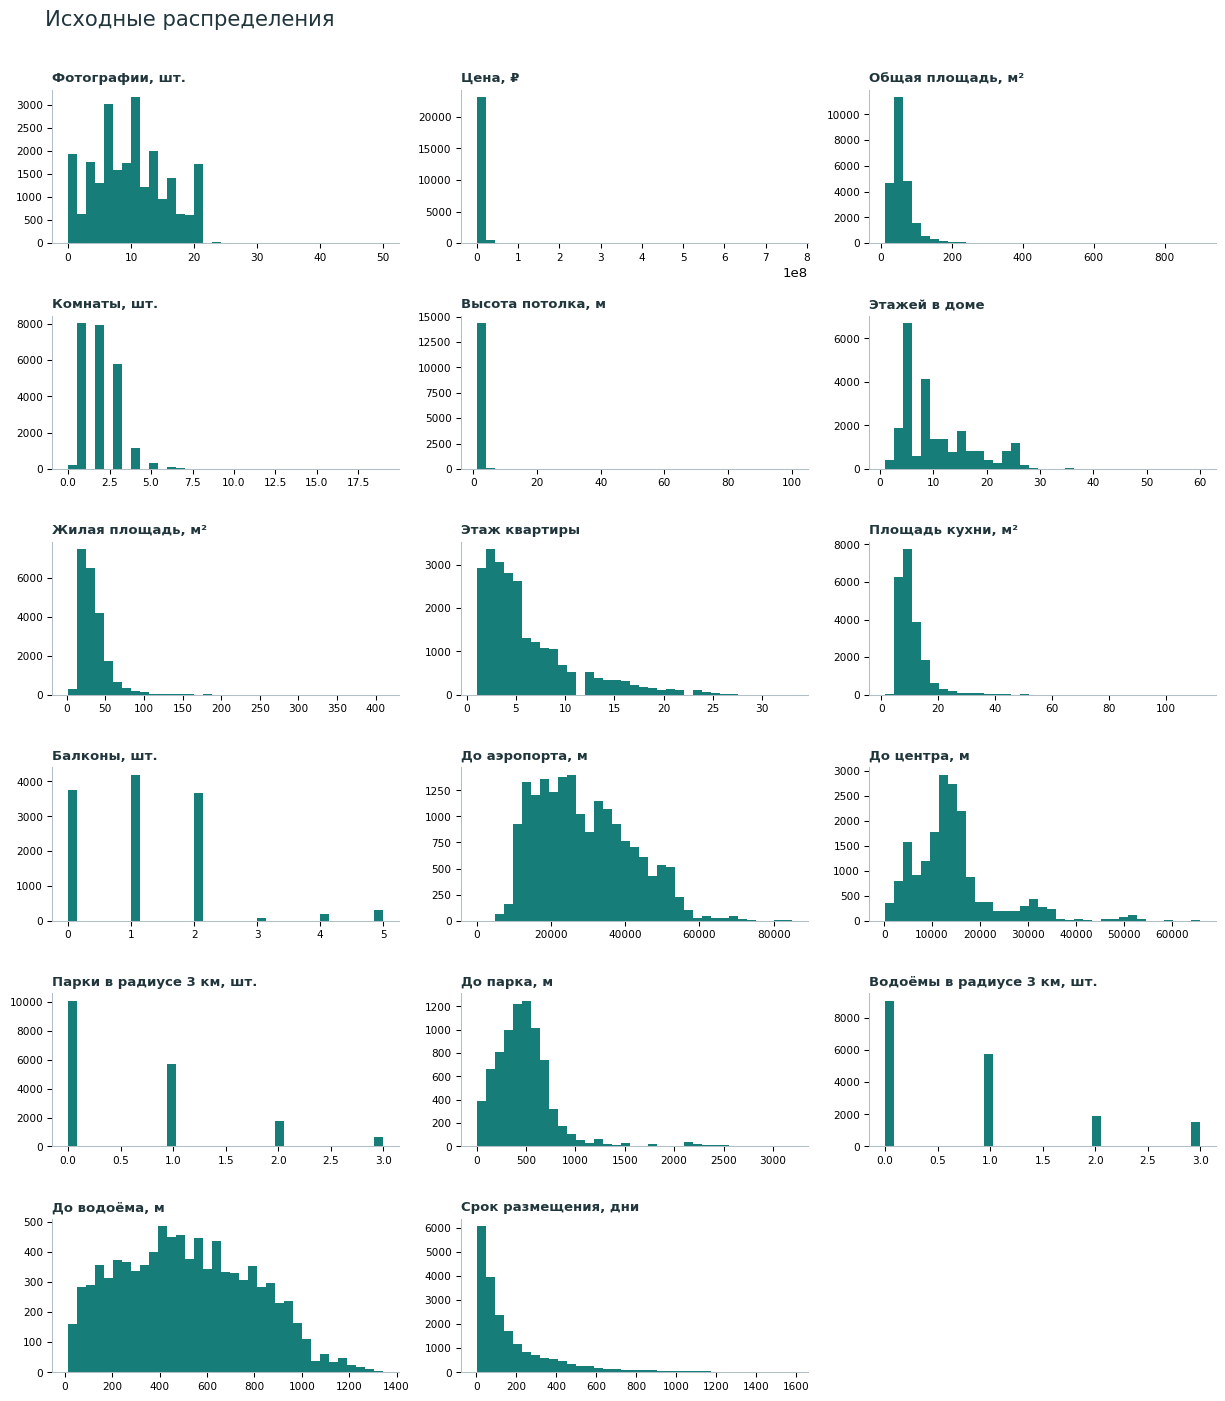

In [4]:
raw_labels = {
    "total_images": "Фотографии, шт.", "last_price": "Цена, ₽",
    "total_area": "Общая площадь, м²", "rooms": "Комнаты, шт.",
    "ceiling_height": "Высота потолка, м", "floors_total": "Этажей в доме",
    "living_area": "Жилая площадь, м²", "floor": "Этаж квартиры",
    "kitchen_area": "Площадь кухни, м²", "balcony": "Балконы, шт.",
    "airports_nearest": "До аэропорта, м", "cityCenters_nearest": "До центра, м",
    "parks_around3000": "Парки в радиусе 3 км, шт.", "parks_nearest": "До парка, м",
    "ponds_around3000": "Водоёмы в радиусе 3 км, шт.", "ponds_nearest": "До водоёма, м",
    "days_exposition": "Срок размещения, дни",
}
numeric_raw = raw.select_dtypes(include="number")
axes = numeric_raw.hist(bins=35, layout=(6, 3), figsize=(13, 15), grid=False)
for ax, name in zip(axes.flat, numeric_raw.columns):
    ax.set_title(raw_labels.get(name, name), fontsize=10)
    ax.tick_params(labelsize=8)
fig = axes.flat[0].figure
fig.suptitle("Исходные распределения", x=0.04, ha="left", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=1.4)
plt.show()

На общей шкале цен основная масса объявлений сжата у левого края. Похожие длинные правые хвосты видны у площадей и срока размещения. У высоты потолка крайнее значение достигает 100 м. Разберём подозрительные записи до расчёта показателей.

## 2. Предобработка

### Пропуски и типы данных

Больше всего пропусков в признаке апартаментов (88,3%). Продавец мог пропустить поле независимо от юридического статуса жилья. Сохраним его как «неизвестно». Если продавец пропустил число балконов, по условию задания считаем его равным нулю. В исходной таблице можно отличить такие случаи от явно указанных нулей.

Отсутствие высоты, жилой площади и площади кухни может объясняться необязательностью полей. У студий и объектов со свободной планировкой отдельную кухню могли вовсе не выделять. Подстановка медианы создала бы измерения, которых продавец не сообщал. Этаж квартиры задаёт только нижнюю границу этажности дома, поэтому неизвестную этажность оставим пропуском.

Сопоставим расстояния до парков с числом парков поблизости. Это поможет различить неполное покрытие геосервиса и отсутствие парка в пределах радиуса поиска.

In [5]:
geo_check = pd.crosstab(
    raw["parks_around3000"].map({0: "Ни одного", 1: "Есть", 2: "Есть", 3: "Есть"})
                           .fillna("Количество неизвестно"),
    raw["parks_nearest"].notna().map({True: "Дистанция известна", False: "Нет дистанции"}),
)
geo_check.index.name = "Парки в радиусе 3 км"
geo_check.columns.name = None
display(geo_check)
free_layout = raw["studio"] | raw["open_plan"]
print("Студий и объектов со свободной планировкой:", free_layout.sum())
print("Из них с отдельной площадью кухни:", raw.loc[free_layout, "kitchen_area"].notna().sum())
print("Нулевых значений комнат вне этих двух категорий:", (raw["rooms"].eq(0) & ~free_layout).sum())

,Дистанция известна,Нет дистанции
Парки в радиусе 3 км,,
Есть,8075,0
Количество неизвестно,0,5518
Ни одного,4,10102


Студий и объектов со свободной планировкой: 216
Из них с отдельной площадью кухни: 0
Нулевых значений комнат вне этих двух категорий: 0


Во всех 5 518 строках с неизвестным числом парков отсутствует и расстояние до парка. Среди объявлений с нулём парков в пределах 3 км у четырёх всё же указана дистанция — ближайший парк находится за пределами этого радиуса. Заполнять неизвестные расстояния нулями или средним по городу оснований нет. Это относится и к остальным картографическим полям.

У всех 216 студий и объектов со свободной планировкой отсутствует отдельная площадь кухни. Все 197 объявлений с нулём комнат входят в эти категории. Сохраним ноль комнат в его исходном смысле. Пропуски в сроке экспозиции могут соответствовать активным на дату выгрузки публикациям или отсутствию даты снятия. Для расчёта сроков будем брать только известные значения.

In [6]:
data = raw.rename(columns={"cityCenters_nearest": "city_centers_nearest"}).copy()
data["first_day_exposition"] = pd.to_datetime(
    data["first_day_exposition"], format="%Y-%m-%dT%H:%M:%S", errors="raise"
)
data["balcony"] = data["balcony"].fillna(0)
integer_columns = ["floors_total", "balcony", "parks_around3000", "ponds_around3000", "days_exposition"]
counts = data[integer_columns]
assert (counts.sub(counts.round()).abs().max() < 1e-8).all()
data[integer_columns] = counts.round().astype("Int64")
data["is_apartment"] = data["is_apartment"].astype("boolean")
display(data[["first_day_exposition", *integer_columns, "is_apartment"]].dtypes
        .astype(str).to_frame("Тип после преобразования"))

,Тип после преобразования
first_day_exposition,datetime64[us]
floors_total,Int64
balcony,Int64
parks_around3000,Int64
ponds_around3000,Int64
days_exposition,Int64
is_apartment,boolean


Календарная дата позволяет извлекать день недели, месяц и год. Количество этажей, балконов, парков, водоёмов и дней записываем целыми числами. Проверка перед преобразованием допускает только погрешность машинного представления числа. Типы `Int64` и `boolean` поддерживают пропущенные значения. Площади и расстояния оставляем числовыми, чтобы сохранить исходную точность.

### Названия населённых пунктов

Сверим перечень названий и частоты вариантов. Формы «городской посёлок» и «посёлок городского типа» приведём к одному обозначению, так же поступим с посёлками при станции. Для Мурино, Кудрово и Рябово зададим соответствия явно. Тип населённого пункта помогает различать тёзок. Например, в выгрузке встречаются и город Никольское, и село Никольское.

In [7]:
names = data["locality_name"].astype("string")
locality = (names.str.strip()
                 .str.replace(r"\s+", " ", regex=True)
                 .str.replace("поселок", "посёлок", regex=False)
                 .str.replace(r"^городской посёлок ", "посёлок городского типа ", regex=True)
                 .str.replace(r"^посёлок при железнодорожной станции ", "посёлок станции ", regex=True))
locality = locality.replace({
    "посёлок Мурино": "Мурино",
    "деревня Кудрово": "Кудрово",
    "посёлок Рябово": "посёлок городского типа Рябово",
})
data["locality"] = locality

name_counts = (data.dropna(subset=["locality"])
                   .groupby(["locality", "locality_name"]).size().rename("Объявления").reset_index())
duplicate_names = name_counts[name_counts.duplicated("locality", keep=False)]
print(f"Вариантов в исходном перечне: {names.nunique()}. После объединения: {locality.nunique()}.")
examples = ["Мурино", "Кудрово", "посёлок городского типа Рябово", "посёлок Тельмана"]
display(duplicate_names.loc[duplicate_names["locality"].isin(examples)].rename(columns={
    "locality": "После объединения", "locality_name": "Исходная запись",
}).reset_index(drop=True))

Вариантов в исходном перечне: 364. После объединения: 318.


,После объединения,Исходная запись,Объявления
0,Кудрово,Кудрово,173
1,Кудрово,деревня Кудрово,299
2,Мурино,Мурино,34
3,Мурино,поселок Мурино,34
4,Мурино,посёлок Мурино,522
5,посёлок Тельмана,поселок Тельмана,2
6,посёлок Тельмана,посёлок Тельмана,39
7,посёлок городского типа Рябово,поселок Рябово,2
8,посёлок городского типа Рябово,поселок городского типа Рябово,1
9,посёлок городского типа Рябово,посёлок городского типа Рябово,1


### Проверка цены, потолков и площадей

Отдельно посмотрим на объявления с минимальной ценой метра и редкими значениями высоты потолков. При конфликте полей сохраним наблюдение для расчётов, которым спорное значение не требуется.

In [8]:
unit_price_raw = data["last_price"].div(data["total_area"])
display(data.assign(price_m2_raw=unit_price_raw).nsmallest(3, "price_m2_raw")
        [["locality_name", "last_price", "total_area", "price_m2_raw"]]
        .rename(columns={"locality_name": "Населённый пункт", "last_price": "Цена, ₽",
                         "total_area": "Площадь, м²", "price_m2_raw": "Цена метра, ₽"}).round(2))
height = data["ceiling_height"]
unusual_height = height.notna() & ~height.between(2, 6)
display(height[unusual_height].value_counts().sort_index()
        .rename_axis("Высота из объявления, м").to_frame("Объявления").T)
print("Этаж квартиры выше указанной этажности дома:", data["floor"].gt(data["floors_total"]).sum())

,Населённый пункт,"Цена, ₽","Площадь, м²","Цена метра, ₽"
8793,Санкт-Петербург,12190.0,109.0,111.83
14911,посёлок станции Свирь,430000.0,54.0,7962.96
4405,Сланцы,500000.0,52.0,9615.38


"Высота из объявления, м",1.00,1.20,1.75,8.00,8.30,10.30,14.00,20.00,22.60,24.00,25.00,26.00,27.00,27.50,32.00,100.00
Объявления,1,1,1,3,1,1,1,1,1,1,7,1,8,1,2,1


Этаж квартиры выше указанной этажности дома: 0


В Петербурге за квартиру площадью 109 м² указали 12 190 ₽, около 112 ₽/м². Следующая по возрастанию цена метра во всём архиве составляет 7 963 ₽/м². Возможна ошибка в единицах цены, но точную сумму установить нельзя. Исключим цену этой записи из денежных расчётов.

Потолки от 20 до 40 м при сдвиге десятичной запятой дают правдоподобные высоты от 2 до 4 м. Для этой группы разделим значение на десять. После коррекции примем рабочий интервал от 2 до 6 м включительно. Значения 1–1,75, 8–14 и 100 м нельзя однозначно восстановить. У таких квартир исключим только высоту.

Проверим также составляющие общей площади. При превышении суммы жилой и кухонной площадей над общей более чем на 0,5 м² исключим обе составляющие, поскольку источник не указывает, в каком поле ошибка. Допуск 0,5 м² учитывает округление измерений. Саму общую площадь используем как заявленную продавцом, с учётом этой неопределённости.

In [9]:
bad_price = (
    data["last_price"].le(0)
    | (data["last_price"].eq(12_190) & data["total_area"].eq(109)
       & data["locality"].eq("Санкт-Петербург"))
)
data.loc[bad_price, "last_price"] = np.nan

decimal_shift = data["ceiling_height"].between(20, 40)
data.loc[decimal_shift, "ceiling_height"] /= 10
bad_height = data["ceiling_height"].notna() & ~data["ceiling_height"].between(2, 6)
data.loc[bad_height, "ceiling_height"] = np.nan

bad_total = data["total_area"].le(0)
data.loc[bad_total, "total_area"] = np.nan
area_parts = ["living_area", "kitchen_area"]
for column in area_parts:
    bad_component = data[column].le(0) | data[column].gt(data["total_area"])
    data.loc[bad_component, column] = np.nan
area_conflict = data["living_area"].add(data["kitchen_area"]).gt(data["total_area"] + 0.5)
data.loc[area_conflict, area_parts] = np.nan

display(pd.Series({
    "Цена исключена": bad_price.sum(),
    "Высота потолка исправлена": decimal_shift.sum(),
    "Высота потолка исключена": bad_height.sum(),
    "Противоречие жилой и кухонной площадей": area_conflict.sum(),
    "Строк в подготовленной таблице": len(data),
}, name="Количество").to_frame())

,Количество
Цена исключена,1
Высота потолка исправлена,22
Высота потолка исключена,10
Противоречие жилой и кухонной площадей,61
Строк в подготовленной таблице,23699


## 3. Расчёт новых признаков

Цену квадратного метра рассчитаем для каждого объявления отдельно и округлим до копеек. Для графиков переведём полную цену в миллионы рублей. День недели закодируем от 0 (понедельник) до 6 (воскресенье). Расстояния до центра сгруппируем по ближайшему целому километру. В группу «0 км» попадают объекты ближе 500 м, в «1 км» — от 500 м включительно до 1 500 м исключительно.

Первый этаж определим по номеру этажа, в том числе в одноэтажном доме. Чтобы отнести квартиру на более высоком этаже к последнему или другому, нужна этажность дома. При её отсутствии оставим тип такого этажа неизвестным.

In [10]:
data["price_m2"] = data["last_price"].div(data["total_area"]).round(2)
data["price_mln"] = data["last_price"].div(1_000_000)
published = data["first_day_exposition"].dt
data["weekday"] = published.dayofweek
data["month"] = published.month
data["year"] = published.year
data["center_km"] = np.floor(data["city_centers_nearest"].div(1000) + 0.5).astype("Int64")

known_floor = data["floors_total"].notna()
floor_type = pd.Series(pd.NA, index=data.index, dtype="string")
floor_type.loc[known_floor & data["floor"].lt(data["floors_total"])] = "другой"
floor_type.loc[data["floor"].eq(data["floors_total"])] = "последний"
floor_type.loc[data["floor"].eq(1)] = "первый"
data["floor_type"] = pd.Categorical(floor_type, categories=["первый", "другой", "последний"])

features = ["price_m2", "price_mln", "weekday", "month", "year", "floor_type", "center_km"]
display(pd.DataFrame({
    "Заполнено": data[features].count(),
    "Пропуски": data[features].isna().sum(),
    "Уникальных значений": data[features].nunique(),
}))
assert data.index.equals(raw.index)
assert data["weekday"].between(0, 6).all()
assert data["price_m2"].dropna().gt(0).all()

,Заполнено,Пропуски,Уникальных значений
price_m2,23698,1,14652
price_mln,23698,1,2977
weekday,23699,0,7
month,23699,0,12
year,23699,0,6
floor_type,23616,83,3
center_km,18180,5519,61


## 4. Исследовательский анализ

### 4.1. Какие квартиры выставляли на продажу

Начну с десяти характеристик квартиры, дома и его окружения. Для каждого числового признака выбираю свою шкалу. Например, для общей площади показываю до 200 м², для кухни — до 36 м². Так можно разглядеть различия среди самых частых предложений. Над каждой диаграммой указана доля известных значений, попавших в её диапазон. Медианы и квартили в таблице считаю по всем известным значениям.

In [11]:
# Поле, подпись, единица измерения, левая и правая границы, ширина интервала.
distributions = [
    ("total_area", "Общая площадь", "м²", 0, 200, 5),
    ("living_area", "Жилая площадь", "м²", 0, 120, 4),
    ("kitchen_area", "Площадь кухни", "м²", 0, 36, 1),
    ("price_mln", "Цена квартиры", "млн ₽", 0, 36, 1),
    ("rooms", "Количество комнат", "комнат", 0, 6, 1),
    ("ceiling_height", "Высота потолков", "м", 2, 4, 0.05),
    ("floors_total", "Этажность дома", "этажей", 1, 30, 1),
    ("city_centers_nearest", "Расстояние до центра", "м", 0, 50_000, 1_000),
    ("parks_nearest", "Расстояние до ближайшего парка", "м", 0, 2_000, 50),
]
summary_rows = []
for field, title, unit, low, high, step in distributions:
    known = data[field].dropna()
    summary_rows.append({
        "Параметр": f"{title}, {unit}", "Заполнено": len(known),
        "25%": known.quantile(0.25), "Медиана": known.median(),
        "75%": known.quantile(0.75),
    })
display(pd.DataFrame(summary_rows).set_index("Параметр").round(2))

,Заполнено,25%,Медиана,75%
Параметр,,,,
"Общая площадь, м²",23699,40.00,52.00,69.9
"Жилая площадь, м²",21735,18.60,30.00,42.3
"Площадь кухни, м²",21360,7.00,9.10,12.0
"Цена квартиры, млн ₽",23698,3.40,4.65,6.8
"Количество комнат, комнат",23699,1.00,2.00,3.0
"Высота потолков, м",14494,2.51,2.65,2.8
"Этажность дома, этажей",23613,5.00,9.00,16.0
"Расстояние до центра, м",18180,9238.00,13098.50,16293.0
"Расстояние до ближайшего парка, м",8079,288.00,455.00,612.0


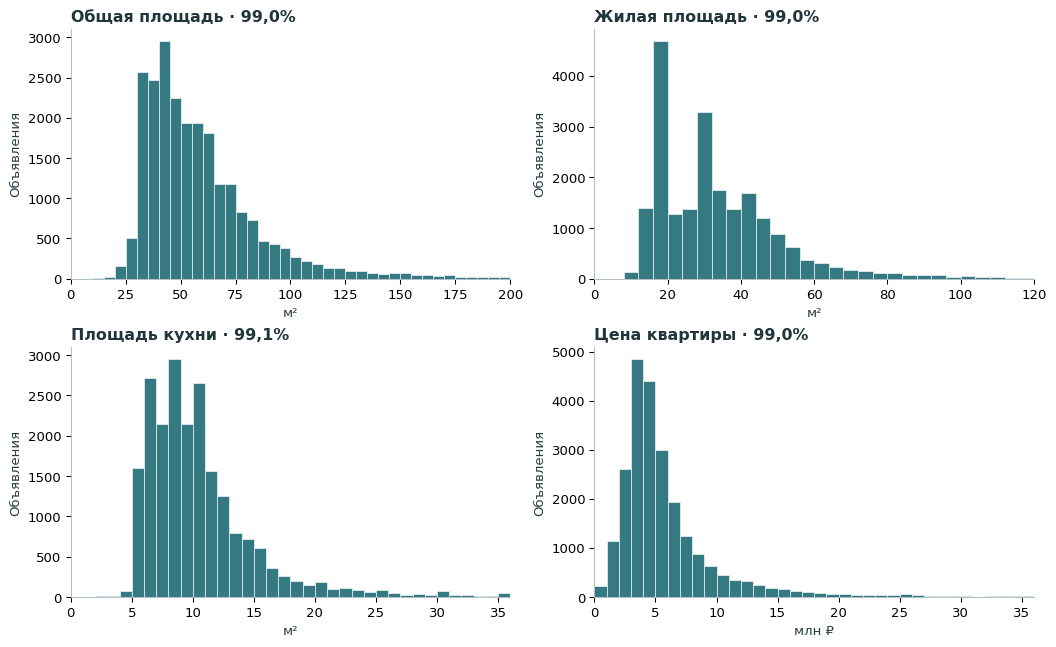

In [12]:
def plot_distribution(ax, spec):
    field, title, unit, low, high, step = spec
    known = data[field].dropna().astype(float)
    visible = known[known.between(low, high)]
    if field in ("rooms", "floors_total"):
        bins = np.arange(low - 0.5, high + 1.5, 1)
        ax.set_xticks(np.arange(low, high + 1, 1 if field == "rooms" else 3))
    else:
        bins = np.linspace(low, high, round((high - low) / step) + 1)
    ax.hist(visible, bins=bins, color="#357982", edgecolor="white", linewidth=0.45)
    ax.set_xlim(bins[0], bins[-1])
    coverage = 100 * len(visible) / len(known)
    ax.set_title(f"{title} · {coverage:.1f}%".replace(".", ","), loc="left", fontsize=12)
    ax.set(xlabel=unit, ylabel="Объявления")

fig, axes = plt.subplots(2, 2, figsize=(11, 6.7), constrained_layout=True)
for ax, spec in zip(axes.flat, distributions[:4]):
    plot_distribution(ax, spec)
plt.show()

Половина предложений укладывается в диапазон **40–70 м² общей площади**, медиана составляет 52 м². У жилой части медиана 30 м², у кухни — 9,1 м². Половина кухонь занимает от 7 до 12 м². На графике цены виден длинный правый хвост. У половины квартир цена лежит между **3,4 и 6,8 млн ₽**, у четверти она выше 6,8 млн ₽.

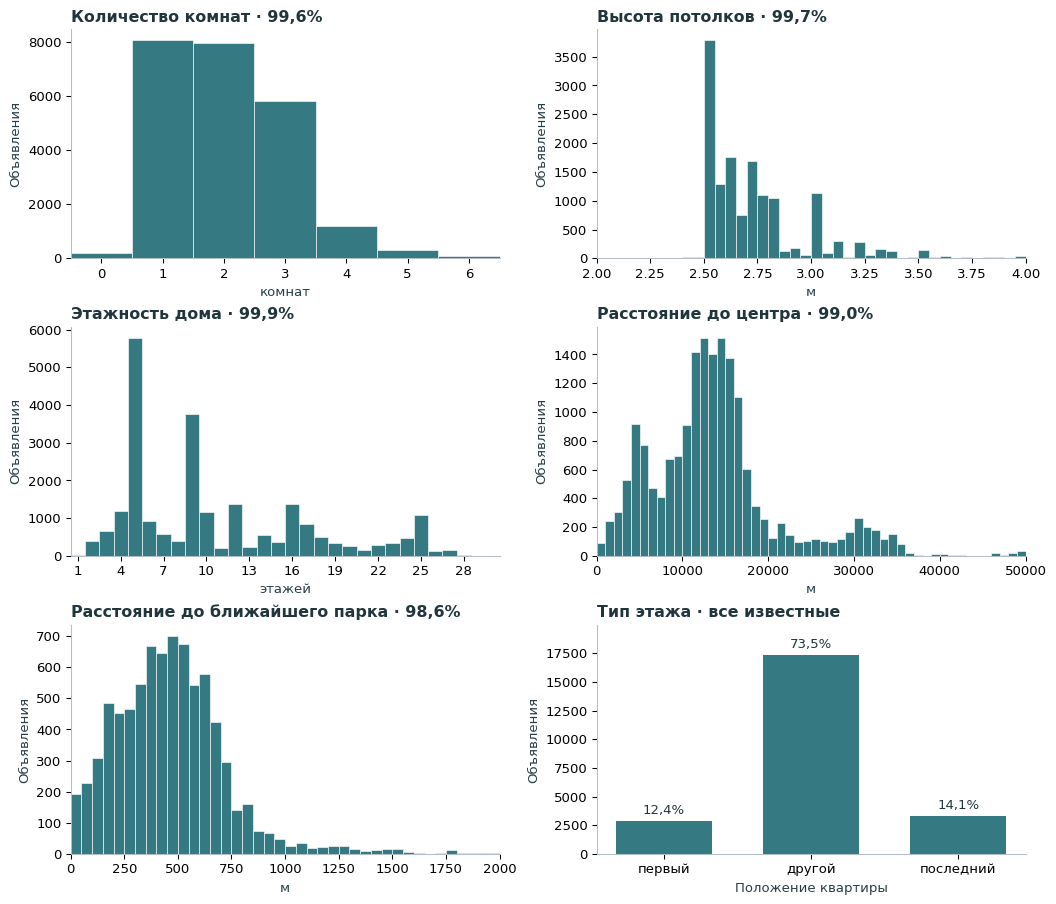

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9.4), constrained_layout=True)
for ax, spec in zip(axes.flat[:5], distributions[4:]):
    plot_distribution(ax, spec)

floor_order = ["первый", "другой", "последний"]
floor_counts = data["floor_type"].value_counts().reindex(floor_order, fill_value=0)
ax = axes.flat[-1]
floor_bars = ax.bar(floor_counts.index, floor_counts.values, color="#357982", width=0.65)
ax.bar_label(floor_bars, labels=[f"{n / floor_counts.sum():.1%}".replace(".", ",")
                                 for n in floor_counts], padding=3)
ax.margins(y=0.15)
ax.set_title("Тип этажа · все известные", loc="left", fontsize=12)
ax.set(xlabel="Положение квартиры", ylabel="Объявления")
plt.show()

В 92% объявлений указано от одной до трёх комнат. Чаще всего встречаются однокомнатные и двухкомнатные квартиры, их почти поровну. Около 74% квартир с известным типом этажа находятся между первым и последним. Среди домов выделяются пяти- и девятиэтажки. В них вместе расположены около 40% предложений с известной этажностью. Самая частая высота потолков — 2,5 м, медиана — 2,65 м.

У объявлений с измеренным расстоянием до центра медиана составляет 13,1 км, а центральные 50% значений лежат между 9,2 и 16,3 км. Для ближайшего парка медиана — 455 м. Расстояние до парка есть только у 8 079 квартир, поэтому по этому числу трудно судить о доступности парков во всей выборке.

### 4.2. Сколько времени объявление оставалось на сайте

У части объявлений указан срок от публикации до снятия. По нему можно оценить, как долго предложение оставалось на сайте. Чтобы установить дату самой сделки, потребовались бы сведения о продаже.

,Значение
"Известен срок, объявлений",20518.0
"Срок неизвестен, объявлений",3181.0
"Среднее, дней",180.9
"Медиана, дней",95.0
"Первый квартиль, дней",45.0
"Третий квартиль, дней",232.0
"Верхняя граница по правилу 1,5 IQR, дней",512.5
"Сняты не позднее первого квартиля, %",29.1
"Дольше верхней границы, %",8.1


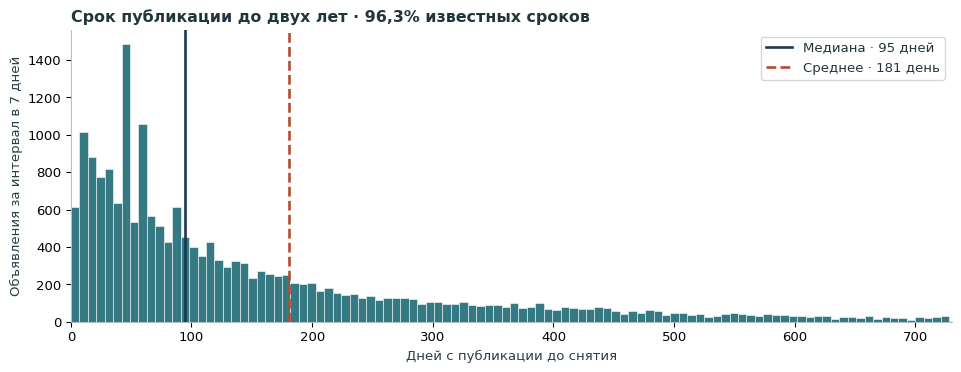

In [14]:
duration = data["days_exposition"].dropna().astype(float)
q1, median_days, q3 = duration.quantile([0.25, 0.50, 0.75])
mean_days = duration.mean()
long_limit = q3 + 1.5 * (q3 - q1)

duration_summary = pd.Series({
    "Известен срок, объявлений": len(duration),
    "Срок неизвестен, объявлений": data["days_exposition"].isna().sum(),
    "Среднее, дней": mean_days, "Медиана, дней": median_days,
    "Первый квартиль, дней": q1, "Третий квартиль, дней": q3,
    "Верхняя граница по правилу 1,5 IQR, дней": long_limit,
    "Сняты не позднее первого квартиля, %": 100 * duration.le(q1).mean(),
    "Дольше верхней границы, %": 100 * duration.gt(long_limit).mean(),
}, name="Значение")
display(duration_summary.round(1).to_frame())

upper_day = 730
visible = duration[duration <= upper_day]
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
bins = np.arange(0, upper_day + 7, 7)
ax.hist(visible, bins=bins, color="#357982", edgecolor="white", linewidth=0.4)
ax.axvline(median_days, color="#1a384f", linewidth=2, label=f"Медиана · {median_days:.0f} дней")
ax.axvline(mean_days, color="#b44c30", linestyle="--", linewidth=2, label=f"Среднее · {mean_days:.0f} день")
ax.set_title(f"Срок публикации до двух лет · {len(visible) / len(duration):.1%} известных сроков"
             .replace(".", ","), loc="left")
ax.set(xlim=(0, upper_day), xlabel="Дней с публикации до снятия", ylabel="Объявления за интервал в 7 дней")
ax.legend()
plt.show()

**Обычный срок публикации — около трёх месяцев.** Половину объявлений с известным сроком сняли за 95 дней, среднее составило 181 день. Оно выше из-за карточек, которые оставались на сайте много месяцев. У центральной половины объявлений срок составляет от 45 до 232 дней.

Быстрыми я считаю снятия за **45 дней или меньше**. Это нижний квартиль. В него попадает 29,1% объявлений с известным сроком, потому что много карточек закрыли ровно на 45-й день. Необычно долгий срок определяю по верхней границе Тьюки, то есть к третьему квартилю прибавляю полтора межквартильных размаха. Получается **от 513 дней**, таких объявлений 8,1%. Оба порога относятся к этому архиву. К концу периода часть квартир могла ещё оставаться на сайте. Например, из 2 879 публикаций 2019 года срок указан только у 1 083.

### 4.3. Как характеристики квартиры связаны с её полной ценой

Сначала проверю, насколько согласованно меняются цена и размер квартиры. Коэффициент Спирмена сравнивает ранги и улавливает связь, даже если цена растёт с площадью неравномерно. Коэффициент Пирсона показывает линейную связь и чувствительнее к крайним значениям. Для каждого признака беру все объявления, где известны и он, и полная цена квартиры.

In [15]:
price_factors = {
    "total_area": "Общая площадь", "living_area": "Жилая площадь",
    "kitchen_area": "Площадь кухни", "rooms": "Количество комнат",
}
correlations = []
for field, title in price_factors.items():
    pair = data[[field, "price_mln"]].dropna().astype(float)
    correlations.append({
        "Признак": title, "Объявления": len(pair),
        "Спирмен": pair.rank().corr().iloc[0, 1],
        "Пирсон": pair.corr().iloc[0, 1],
    })
display(pd.DataFrame(correlations).set_index("Признак").round(3))

,Объявления,Спирмен,Пирсон
Признак,,,
Общая площадь,23698,0.749,0.654
Жилая площадь,21734,0.641,0.567
Площадь кухни,21359,0.582,0.522
Количество комнат,23698,0.539,0.363


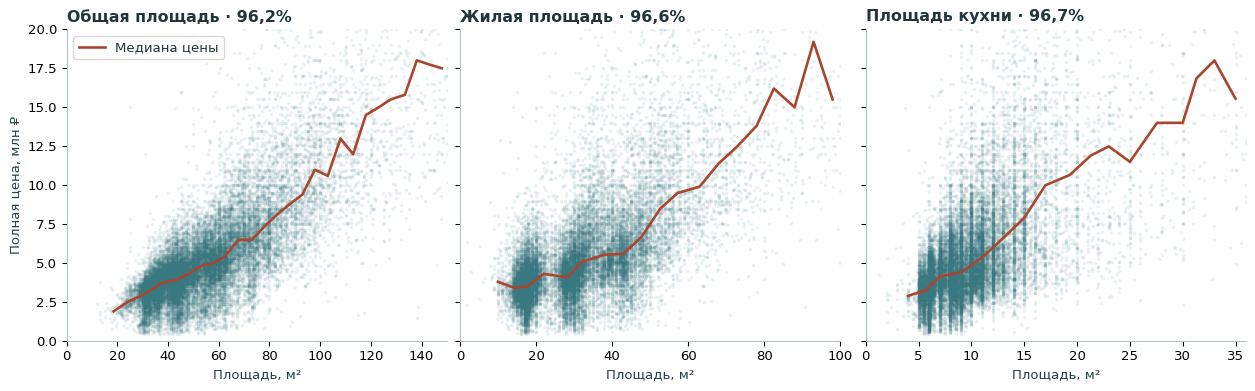

In [16]:
area_scales = [("total_area", 150, 5), ("living_area", 100, 5), ("kitchen_area", 36, 2)]
fig, axes = plt.subplots(1, 3, figsize=(13.1, 4), sharey=True, constrained_layout=True)
for ax, (field, max_area, step) in zip(axes, area_scales):
    pair = data[[field, "price_mln"]].dropna().astype(float)
    on_plot = pair[field].le(max_area) & pair["price_mln"].le(20)
    visible = pair.loc[on_plot]
    ax.scatter(visible[field], visible["price_mln"], s=7, alpha=0.1, color="#377881",
               linewidths=0, rasterized=True)
    # Для медианы в каждом интервале площади используем и квартиры дороже 20 млн.
    edges = np.arange(0, max_area + step, step)
    area_groups = pd.cut(pair[field], bins=edges, include_lowest=True)
    trend = pair.groupby(area_groups, observed=True).agg(
        x=(field, "median"), y=("price_mln", "median"), n=("price_mln", "size"))
    trend = trend[trend["n"] >= 20]
    ax.plot(trend["x"], trend["y"], color="#a9462e", linewidth=2, label="Медиана цены")
    ax.set_title(f"{price_factors[field]} · {on_plot.mean():.1%}".replace(".", ","),
                 loc="left", fontsize=12)
    ax.set(xlim=(0, max_area), ylim=(0, 20), xlabel="Площадь, м²")
axes[0].set_ylabel("Полная цена, млн ₽")
axes[0].legend(loc="upper left")
plt.show()

Сильнейшая из измеренных связей — между **полной ценой и общей площадью**. Коэффициент Спирмена равен 0,75. Для жилой площади он составляет 0,64, для площади кухни — 0,58, для числа комнат — 0,54. По Пирсону порядок тот же. Общая площадь включает жилую часть и кухню, поэтому эти коэффициенты нельзя складывать для оценки вклада отдельных метров.

Каждая точка на графике — одно объявление. Рядом с названием указана доля известных пар, видимых на обеих осях. Линия соединяет медианы цены в интервалах по 5 м² для общей и жилой площади и по 2 м² для кухни. Для каждой точки линии потребовалось хотя бы 20 объявлений. При одинаковой площади разброс цен остаётся большим.

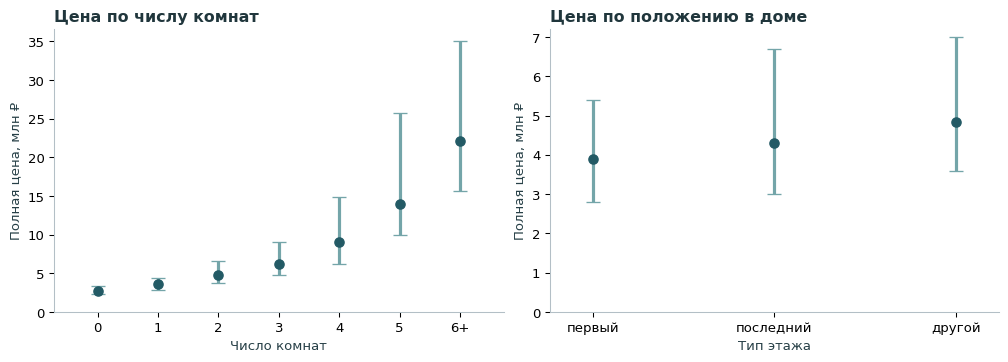

In [17]:
# «6+» объединяет малочисленные группы больших квартир только на диаграмме.
room_groups = data["rooms"].clip(upper=6)
room_prices = data["price_mln"].groupby(room_groups).quantile([0.25, 0.5, 0.75]).unstack()
room_prices = room_prices.reindex(range(7))
room_prices.index = ["0", "1", "2", "3", "4", "5", "6+"]
floor_prices = data.groupby("floor_type")["price_mln"].quantile([0.25, 0.5, 0.75]).unstack()
floor_prices = floor_prices.reindex(["первый", "последний", "другой"])

def plot_price_groups(ax, quartiles, title, x_label):
    x = np.arange(len(quartiles))
    median = quartiles[0.5]
    ax.errorbar(x, median, yerr=[median - quartiles[0.25], quartiles[0.75] - median],
                fmt="o", color="#235a65", ecolor="#74a5a9", capsize=5,
                linewidth=2.4, markersize=7)
    ax.set_xticks(x, quartiles.index)
    ax.margins(x=0.12)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set(xlabel=x_label, ylabel="Полная цена, млн ₽")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), constrained_layout=True)
plot_price_groups(axes[0], room_prices, "Цена по числу комнат", "Число комнат")
plot_price_groups(axes[1], floor_prices, "Цена по положению в доме", "Тип этажа")
for ax in axes:
    ax.set_ylim(bottom=0)
plt.show()

Точка соответствует медианной цене группы, отрезок охватывает средние 50% цен. У однокомнатных квартир медиана составляет **3,60 млн ₽**, у двухкомнатных — **4,77 млн ₽**, у трёхкомнатных — **6,20 млн ₽**. При этом комнаты и метры меняются вместе. Из разницы между группами нельзя вывести стоимость дополнительной комнаты при фиксированном метраже.

По этажам самая низкая медиана у квартир **на первом этаже — 3,90 млн ₽**. На последнем этаже она составляет 4,30 млн ₽, между первым и последним — 4,85 млн ₽. Диапазоны заметно перекрываются. В этих сравнениях не учтены различия в районах и типах домов.

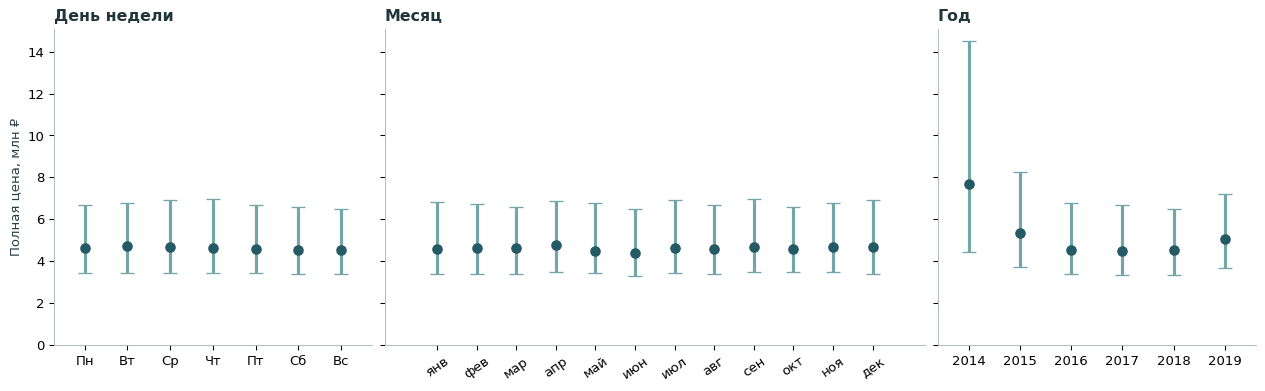

,Объявления,Известен срок,"Медианная цена, млн ₽","Медианная площадь, м²"
Год публикации,,,,
2014,137,119,7.70,76.26
2015,1191,1121,5.35,60.00
2016,2783,2716,4.55,53.10
2017,8190,7919,4.50,52.00
2018,8519,7560,4.55,50.50
2019,2879,1083,5.05,52.00


In [18]:
calendar_axes = [
    ("weekday", range(7), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"], "День недели"),
    ("month", range(1, 13), ["янв", "фев", "мар", "апр", "май", "июн",
                              "июл", "авг", "сен", "окт", "ноя", "дек"], "Месяц"),
    ("year", sorted(data["year"].dropna().unique()), None, "Год"),
]
fig, axes = plt.subplots(1, 3, figsize=(13.2, 4), sharey=True,
                         gridspec_kw={"width_ratios": [1, 1.7, 1]}, constrained_layout=True)
for ax, (field, order, labels, title) in zip(axes, calendar_axes):
    quartiles = data.groupby(field)["price_mln"].quantile([0.25, 0.5, 0.75]).unstack().reindex(order)
    if labels is not None:
        quartiles.index = labels
    plot_price_groups(ax, quartiles, title, "")
    if field == "month":
        ax.tick_params(axis="x", labelrotation=35)
for ax in axes[1:]:
    ax.set_ylabel("")
axes[0].set_ylim(bottom=0)
plt.show()

by_year = data.groupby("year").agg(
    Объявления=("total_area", "size"), Срок=("days_exposition", "count"),
    Цена=("price_mln", "median"), Площадь=("total_area", "median"))
by_year.columns = ["Объявления", "Известен срок", "Медианная цена, млн ₽", "Медианная площадь, м²"]
display(by_year.rename_axis("Год публикации").round(2))

По дням недели медианы укладываются в **4,55–4,73 млн ₽**. По месяцам минимум выпадает на июнь (4,40 млн ₽), максимум — на апрель (4,80 млн ₽). Различия малы по сравнению с разбросом внутри каждой группы. Оснований считать день публикации надёжным ориентиром для оценки цены я здесь не вижу.

По полным годам сильнее всего отличаются 2015 и 2016 годы. Медианная цена снизилась с 5,35 до 4,55 млн ₽, вместе с ней уменьшилась и медианная площадь — с 60 до 53,1 м². В 2016–2018 годах медиана цены оставалась в пределах 4,50–4,55 млн ₽. В 2014 году в архив попали только ноябрь и декабрь и всего 137 объявлений. В 2019 году наблюдения обрываются 3 мая. Состав предложения и неполные периоды мешают трактовать ряд как изменение цены одной и той же квартиры.

### 4.4. Десять населённых пунктов с наибольшим числом объявлений

Сначала я отобрал десятку по числу всех объявлений с известным названием. Затем для каждого места посчитал среднее индивидуальных цен за квадратный метр. У каждой квартиры одинаковый вес. В таблице видно, сколько цен вошло в расчёт.

In [19]:
locality_stats = (
    data.dropna(subset=['locality']).groupby('locality')
    .agg(ads=('locality', 'size'), prices=('price_m2', 'count'), mean_m2=('price_m2', 'mean'))
    .sort_values('ads', ascending=False).head(10)
)
display(locality_stats.rename_axis('Населённый пункт').rename(columns={
    'ads': 'Объявлений', 'prices': 'С ценой за м²', 'mean_m2': 'Средняя цена, ₽/м²',
}).round(2))

,Объявлений,С ценой за м²,"Средняя цена, ₽/м²"
Населённый пункт,,,
Санкт-Петербург,15721,15720,114856.31
Мурино,590,590,86087.51
Кудрово,472,472,95324.93
посёлок Шушары,440,440,78677.36
Всеволожск,398,398,68654.47
Пушкин,369,369,103125.82
Колпино,338,338,75424.58
посёлок Парголово,327,327,90175.91
Гатчина,307,307,68746.15


Петербург лидирует и по числу объявлений (15 721), и по средней цене метра (114,9 тыс. ₽). В Выборге метр стоил в среднем 58,1 тыс. ₽ по 237 объявлениям. Разрыв почти двукратный. Среди ближайших к Петербургу населённых пунктов цены тоже различались. В Кудрово среднее составило 95,3 тыс. ₽/м², в Мурино — 86,1 тыс. ₽/м².

### 4.5. Сколько просили за квартиру на разном расстоянии от центра

Здесь оставляю только Санкт-Петербург и считаю **полную цену квартиры** в каждом километровом интервале. Интервал «0 км» содержит адреса ближе половины километра. Рядом со средним показываю медиану и число наблюдений, чтобы дорогие квартиры и малые группы было проще заметить.

In [20]:
petersburg = data.loc[data['locality'].eq('Санкт-Петербург')]
priced_city = petersburg.dropna(subset=['center_km', 'price_mln'])
by_km = (priced_city.groupby('center_km')['price_mln']
         .agg(ads='size', mean_price='mean', median_price='median')
         .sort_index())
print(f'Из {len(petersburg):,} объявлений Петербурга для графика пригодны {len(priced_city):,}.'
      .replace(',', ' '))
display(by_km.rename_axis('Расстояние, км').rename(columns={
    'ads': 'Объявлений', 'mean_price': 'Средняя, млн ₽', 'median_price': 'Медиана, млн ₽',
}).round(2))

Из 15 721 объявлений Петербурга для графика пригодны 15 659.


,Объявлений,"Средняя, млн ₽","Медиана, млн ₽"
"Расстояние, км",,,
0,27,31.45,17.90
1,192,21.21,11.40
2,310,17.79,10.00
3,350,11.13,8.41
4,686,13.31,9.20
5,922,14.49,9.50
6,618,15.34,8.90
7,420,14.78,7.80
8,597,9.96,7.45


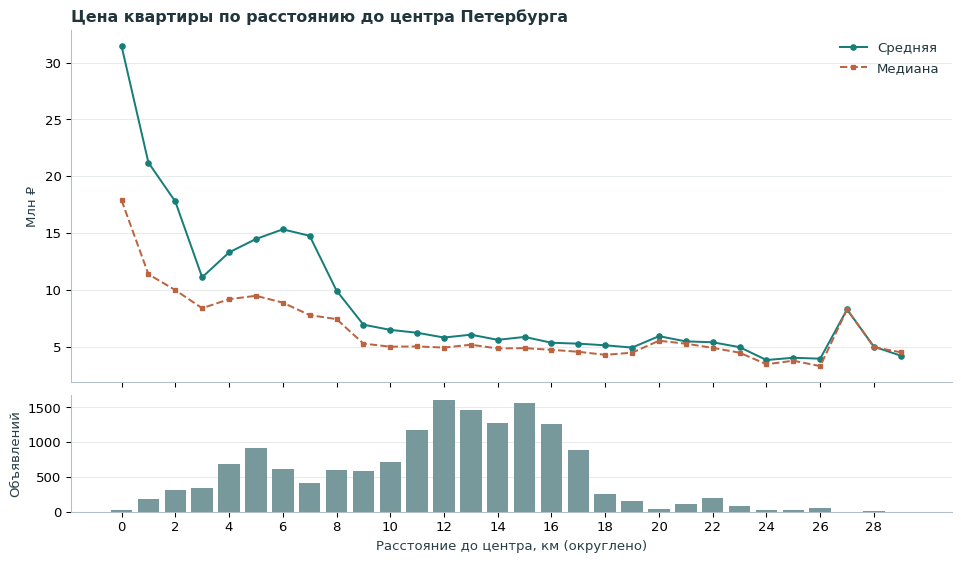

In [21]:
km = by_km.index.to_numpy(dtype=float)
fig, (price_ax, count_ax) = plt.subplots(
    2, 1, figsize=(10, 5.8), sharex=True, height_ratios=[3, 1], layout='constrained'
)
price_ax.plot(km, by_km['mean_price'], marker='o', ms=4, label='Средняя')
price_ax.plot(km, by_km['median_price'], marker='s', ms=3, ls='--', label='Медиана')
price_ax.set(title='Цена квартиры по расстоянию до центра Петербурга', ylabel='Млн ₽')
price_ax.legend(frameon=False)
price_ax.grid(axis='y')
count_ax.bar(km, by_km['ads'], color='#78999b', width=.8)
count_ax.set(xlabel='Расстояние до центра, км (округлено)', ylabel='Объявлений')
count_ax.set_xticks(range(0, int(km.max()) + 1, 2))
count_ax.grid(axis='y')
plt.show()

На расстоянии 1 км от центра квартиру выставляли в среднем за 21,21 млн ₽ (192 объявления), на 10 км — за 6,51 млн ₽ (716), на 15 км — за 5,88 млн ₽ (1 568). Снижение заметно в целом, но между соседними километрами бывают подъёмы. На 27 км среднее подскочило до 8,30 млн ₽ всего по двум объявлениям. Судить по ним о ценах всего района трудно.

Ближе половины километра к центру средняя цена равна 31,45 млн ₽, а медианная — 17,90 млн ₽. Несколько дорогих объектов заметно влияют на среднее. Кроме того, в центре и на окраинах могут различаться площадь и состав квартир.

## 5. Что я бы учёл при оценке квартиры

Для первого ориентира я бы подобрал объявления в том же населённом пункте с близкой общей площадью. В Петербурге сузил бы поиск до сопоставимого расстояния от центра, а затем сравнил этаж, число комнат и цену метра. Коэффициент Спирмена между площадью и полной ценой составил 0,75. Одного среднего по всему рынку для такой оценки мало.

Для похожих квартир я бы показывал медиану, диапазон и число аналогов. Это особенно важно там, где объявлений единицы. Сильное отличие от аналогов — повод проверить площадь, единицы измерения и описание объекта. По одному отклонению установить мошенничество нельзя.

Медианный срок размещения составил 95 дней среди объявлений с известным сроком. Он может служить историческим ориентиром для публикации. В архиве нет подтверждений продажи, а цены отражают рынок 2014–2019 годов.